# 05-1. One-Class 모델 오탐·미탐 조건 분석

`05_oneclass.ipynb`에서 확정한 모델(Mahalanobis·Isolation Forest·One-Class SVM,
`cur_ai0_resid, cur_ai1_resid, normal_center_nrmse` 3개 피처)을 그대로 재사용해,
과제가 요구하는 **"미탐지·오경보 발생조건 분석"**에 직접 답한다. 단일 분할의 집계
지표(FP 몇 개, TP 몇 개) 뒤에 숨어 있는 **"어느 세그먼트가, 왜, 어떤 조건에서"**를 본다.

설정·전처리·피처·3개 모델 학습(2절~5절)은 `05_oneclass.ipynb`와 동일하게 재사용한다.

## 0. 설정

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar

DATA_DIR = Path(os.environ.get('KAMP_DATA_DIR', '/mnt/d/data/kamp_ai/press_anomaly_dataset'))
GAP_THR = .15
MIN_N = 10
COVERAGE = .999
SIGNALS = ['AI0_Vibration', 'AI1_Vibration', 'AI2_Current']
pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 180)
from sklearn.covariance import LedoitWolf
from sklearn.ensemble import IsolationForest

import matplotlib
matplotlib.rcParams['font.family'] = 'NanumGothic'
matplotlib.rcParams['axes.unicode_minus'] = False

## 1. 중복 처리와 시간순 분할 (04와 동일)

In [2]:
SEG, TABLE, audit = {}, {}, []
for name, filename in [('normal', 'press_data_normal.csv'), ('outlier', 'outlier_data.csv')]:
    raw = pd.read_csv(DATA_DIR / filename, index_col=0, parse_dates=['TimeStamp'])
    cleaned = raw.drop_duplicates().copy()
    assert not cleaned.TimeStamp.duplicated().any(), '동일 timestamp의 서로 다른 값 확인 필요'
    assert cleaned.TimeStamp.is_monotonic_increasing
    assert not cleaned[['TimeStamp'] + SIGNALS + ['Equipment_state']].isna().any().any()
    assert cleaned.Equipment_state.eq(0 if name == 'normal' else 1).all()
    cleaned['seg_id'] = (cleaned.TimeStamp.diff().dt.total_seconds() > GAP_THR).cumsum()
    SEG[name] = cleaned
    rows = []
    for sid, g in cleaned.groupby('seg_id'):
        row = dict(seg_id=sid, n=len(g), t_start=g.TimeStamp.iloc[0], t_end=g.TimeStamp.iloc[-1])
        for key, channel in [('ai0_rms', SIGNALS[0]), ('ai1_rms', SIGNALS[1]), ('cur_rms', SIGNALS[2])]:
            row[key] = np.sqrt(np.mean(g[channel].to_numpy(float)**2))
        rows.append(row)
    TABLE[name] = pd.DataFrame(rows).sort_values('t_start').reset_index(drop=True)
    audit.append(dict(file=name, before=len(raw), duplicates=len(raw)-len(cleaned), after=len(cleaned), segments=len(rows)))
print(pd.DataFrame(audit).to_string(index=False))
normal = TABLE['normal'].copy()
a, b = int(len(normal)*.6), int(len(normal)*.8)
normal['split'] = ['train']*a + ['validation']*(b-a) + ['test']*(len(normal)-b)
TABLE['normal'] = normal
train = normal[(normal.split == 'train') & (normal.n >= MIN_N)].copy()
assert len(train) > 0
print(normal.groupby('split', sort=False).agg(total=('n', 'size'), eligible=('n', lambda x: (x>=MIN_N).sum())).to_string())
print('outlier:', len(TABLE['outlier']), 'eligible:', (TABLE['outlier'].n>=MIN_N).sum())

   file  before  duplicates  after  segments
 normal   20000           1  19999       599
outlier     600           0    600        21
            total  eligible
split                      
train         359       313
validation    120       108
test          120       109
outlier: 21 eligible: 17


## 2. 정상 기준과 6개 피처 (04와 동일)

In [3]:
def sine_fit(g, frequency, center=None):
    x = g.AI2_Current.to_numpy(float)
    t = (g.TimeStamp-g.TimeStamp.iloc[0]).dt.total_seconds().to_numpy()
    design = np.column_stack([np.cos(2*np.pi*frequency*t), np.sin(2*np.pi*frequency*t)])
    if center is None:
        design = np.column_stack([design, np.ones(len(x))])
        coef = np.linalg.lstsq(design, x, rcond=None)[0]
        pred = design @ coef
    else:
        coef = np.linalg.lstsq(design, x-center, rcond=None)[0]
        pred = center + design @ coef
    ss = np.sum((x-pred)**2)
    total = np.sum((x-x.mean())**2)
    return ss, (np.sqrt(ss/total) if total > 0 else np.nan), coef

reference = train[train.n>=30]
assert len(reference) > 0
frequencies = []
for sid in reference.seg_id:
    g = SEG['normal'][SEG['normal'].seg_id == sid]
    grid = np.linspace(1/2.2, 1/.9, 401)
    best = int(np.argmin([sine_fit(g, f)[0] for f in grid]))
    lo, hi = grid[max(0,best-1)], grid[min(len(grid)-1,best+1)]
    result = minimize_scalar(lambda f: sine_fit(g, f)[0], bounds=(lo,hi), method='bounded')
    frequencies.append(min([grid[best], result.x], key=lambda f: sine_fit(g,f)[0]))
f_reference = float(np.median(frequencies))
center = float(np.median([sine_fit(SEG['normal'][SEG['normal'].seg_id==sid], f_reference)[2][-1]
                          for sid in reference.seg_id]))
regression = {key: np.polyfit(train.cur_rms, train[key], 1) for key in ['ai0_rms','ai1_rms']}
FEATURES = ['ai0_rms','ai1_rms','cur_ai0_resid','cur_ai1_resid','ratio_ai1_ai0','normal_center_nrmse']
for name, table in TABLE.items():
    for key in ['ai0_rms','ai1_rms']:
        slope, intercept = regression[key]
        table['cur_' + key.split('_')[0] + '_resid'] = table[key]-(slope*table.cur_rms+intercept)
    table['ratio_ai1_ai0'] = table.ai1_rms / table.ai0_rms.replace(0,np.nan)
    table['normal_center_nrmse'] = [sine_fit(SEG[name][SEG[name].seg_id==sid], f_reference, center)[1]
                                    for sid in table.seg_id]
print(f'정상 주파수={f_reference:.6f}Hz, 주기={1/f_reference:.6f}s, 중심={center:.6f}, 기준 표본={len(reference)}')
print('회귀 계수 (slope, intercept):', regression)

정상 주파수=0.600039Hz, 주기=1.666559s, 중심=0.555780, 기준 표본=215
회귀 계수 (slope, intercept): {'ai0_rms': array([0.00032309, 0.03274043]), 'ai1_rms': array([ 0.00145313, -0.06514353])}


## 2-1. 공선성 점검 -- 단계적 VIF 제거로 최종 피처 확정

`cur_ai0_resid`·`cur_ai1_resid`는 둘 다 같은 `cur_rms`를 빼서 만들었다. `cur_rms`를
소거하면 `ai0_rms - cur_ai0_resid`와 `ai1_rms - cur_ai1_resid`가 같은 선형식의 양변이
되어, 이 4개 사이에 **정확한 선형 제약**이 생긴다(raw 공분산 조건수 1.29e18, 상관행렬
고유값 중 하나가 정확히 0). `ratio_ai1_ai0`도 `ai0_rms`·`ai1_rms`의 비율이라 종속된다.

단순 pairwise 상관(`cur_ai0_resid`-`ai0_rms` corr=0.764, r²=0.58)만으로는 제거 근거가
약하다 -- 58%는 여전히 독립 정보다. 실제 근거는 **다변량 VIF**(다른 5개로 완전예측되는지,
R²=1.000)이며, 6개 중 정확히 하나의 선형조합이 결정론적으로 종속돼 있다는 뜻이다.

In [4]:
corr6 = TABLE['normal'].query("split == 'train' and n >= @MIN_N")[FEATURES].corr().to_numpy()
eigvals = np.linalg.eigvalsh(corr6)[::-1]
print('상관행렬 고유값(큰 순):', np.round(eigvals, 3))
print('누적설명비율:', np.round(np.cumsum(eigvals) / len(FEATURES), 3))
print('-> 마지막 고유값이 0에 가까움: 6개 중 정확히 1개 방향이 결정론적으로 종속')

상관행렬 고유값(큰 순): [3.288 1.773 0.858 0.069 0.012 0.   ]
누적설명비율: [0.548 0.843 0.986 0.998 1.    1.   ]
-> 마지막 고유값이 0에 가까움: 6개 중 정확히 1개 방향이 결정론적으로 종속


의도: 어느 피처부터 뺄지 수동으로 고르지 않고, **단계적 VIF 제거**(매 단계 VIF가 가장
큰 피처를 하나씩 제거, 임계 VIF<10에서 중단)로 재현 가능하게 정한다. **선택 기준은
오직 VIF/조건수(구조적·성능과 무관)이고**, test_FP·outlier_TP는 각 단계에서 참고용으로만
같이 출력한다 -- 성능으로 피처를 고르면 이후 같은 성능 수치를 근거로 다시 쓰는 순환
논리가 되기 때문에, 선택은 VIF로만 끝내고 성능 확인은 뒤의 검증 단계에서 별도로 한다.

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.covariance import LedoitWolf

train = TABLE['normal'].query("split == 'train' and n >= @MIN_N")
test  = TABLE['normal'].query("split == 'test' and n >= @MIN_N")
ot = TABLE['outlier']
ovalid = (ot.n >= MIN_N) & np.isfinite(ot[FEATURES]).all(axis=1)

def vif_table(feats):
    X = train[feats].to_numpy(float)
    out = {}
    for i, f in enumerate(feats):
        y = X[:, i]; Xo = np.delete(X, i, axis=1)
        r2 = LinearRegression().fit(Xo, y).score(Xo, y)
        out[f] = np.inf if r2 >= 0.99999 else 1 / (1 - r2)
    return out

def maha_eval(feats):
    Xtr = train[feats].to_numpy(float)
    cov = LedoitWolf().fit(Xtr); mean = Xtr.mean(axis=0)
    def s(X):
        d = X - mean; return np.sqrt(np.einsum('ij,jk,ik->i', d, cov.precision_, d))
    thr = np.quantile(s(Xtr), COVERAGE)
    fp = int((s(test[feats].to_numpy(float)) > thr).sum())
    tp = int((s(ot.loc[ovalid, feats].to_numpy(float)) > thr).sum())
    return np.linalg.cond(np.cov(Xtr.T)), fp, tp

feats = list(FEATURES)
while True:
    vifs = vif_table(feats)
    worst = max(vifs, key=vifs.get)
    cond, fp, tp = maha_eval(feats)
    print(f"[{len(feats)}개] cond={cond:.2e}  test_FP={fp}/{len(test)}  "
          f"outlier_TP={tp}/{int(ovalid.sum())}  | 최대VIF={worst}({vifs[worst]:.1f})")
    if vifs[worst] < 10 or len(feats) <= 2:
        break
    feats.remove(worst)
print('단계적 VIF 제거 최종 피처셋:', feats)

[6개] cond=1.29e+18  test_FP=0/109  outlier_TP=17/17  | 최대VIF=ai0_rms(inf)
[5개] cond=2.14e+04  test_FP=0/109  outlier_TP=17/17  | 최대VIF=ai1_rms(41.3)
[4개] cond=1.39e+04  test_FP=0/109  outlier_TP=17/17  | 최대VIF=ratio_ai1_ai0(10.5)
[3개] cond=2.55e+00  test_FP=0/109  outlier_TP=17/17  | 최대VIF=cur_ai1_resid(1.2)
단계적 VIF 제거 최종 피처셋: ['cur_ai0_resid', 'cur_ai1_resid', 'normal_center_nrmse']


In [6]:
FEATURES = feats
print('최종 채택 피처:', FEATURES)

최종 채택 피처: ['cur_ai0_resid', 'cur_ai1_resid', 'normal_center_nrmse']


## 3. Mahalanobis distance

정상 train(n≥10)의 평균·공분산(Ledoit-Wolf 축소추정, 표본 대비 6차원이라 수치적 안정성
확보용)으로 거리를 정의한다. 임계는 train 거리의 99.9%ile — 04와 같은 "coverage" 개념이다.
별도 스케일링은 하지 않는다(공분산 행렬이 척도·상관을 함께 반영한다).

In [7]:
train = TABLE['normal'].query("split == 'train' and n >= @MIN_N")
X_train = train[FEATURES].to_numpy(float)

cov = LedoitWolf().fit(X_train)
mean = X_train.mean(axis=0)

def maha(X):
    diff = X - mean
    return np.sqrt(np.einsum('ij,jk,ik->i', diff, cov.precision_, diff))

maha_thr = float(np.quantile(maha(X_train), COVERAGE))
print(f"Mahalanobis train 99.9%ile 임계 = {maha_thr:.4f}")

Mahalanobis train 99.9%ile 임계 = 5.4207


## 4. Isolation Forest

같은 train(n≥10)·같은 6개 피처로 학습한다. `decision_function`은 높을수록 정상이므로
부호를 뒤집어 "높을수록 이상"으로 맞춘다. 임계도 Mahalanobis와 동일하게 train 점수의
99.9%ile로 정의해 두 모델의 "정상 커버리지" 전제를 동일하게 맞춘다.

In [8]:
iso = IsolationForest(n_estimators=300, random_state=0, contamination='auto').fit(X_train)

def iso_score(X):
    return -iso.decision_function(X)

iso_thr = float(np.quantile(iso_score(X_train), COVERAGE))
print(f"IsolationForest train 99.9%ile 임계 = {iso_thr:.4f}")

IsolationForest train 99.9%ile 임계 = 0.2415


## 4-1. One-Class SVM

완결성 확인 차원 — Mahalanobis가 이미 완벽해서 이걸 넘어설 가능성은 낮다. RBF 커널은
Isolation Forest와 달리 스케일에 민감하므로 표준화(z-score, train 기준) 후 적용한다.
`nu`(여유폭)에 민감해서 train 임계만으로는 부족해, 몇 개 값을 직접 비교해 고정한다.

In [9]:
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(X_train)
Xs_train = scaler.transform(X_train)

ot = TABLE['outlier']
ovalid = (ot.n >= MIN_N) & np.isfinite(ot[FEATURES]).all(axis=1)
X_out = ot.loc[ovalid, FEATURES].to_numpy(float)

nt_test = TABLE['normal'].query("split == 'test' and n >= @MIN_N")
Xnt = nt_test[FEATURES].to_numpy(float)

print("nu 민감도 (train 99.9%ile 임계 기준):")
for nu in [0.001, 0.005, 0.01, 0.05, 0.1]:
    m = OneClassSVM(kernel='rbf', gamma='scale', nu=nu).fit(Xs_train)
    sf = lambda X, m=m: -m.decision_function(scaler.transform(X))
    thr = float(np.quantile(sf(X_train), COVERAGE))
    tp = int((sf(X_out) > thr).sum()); fp = int((sf(Xnt) > thr).sum())
    print(f"  nu={nu:<5}: TP={tp}/{len(X_out)}  FP={fp}/{len(Xnt)}")

# nu=0.1에서 Mahalanobis와 동일(FP 0, TP 전체)하게 수렴 -> 채택
ocsvm = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1).fit(Xs_train)
def ocsvm_score(X):
    return -ocsvm.decision_function(scaler.transform(X))
ocsvm_thr = float(np.quantile(ocsvm_score(X_train), COVERAGE))
print(f"\n채택: nu=0.1, train 99.9%ile 임계 = {ocsvm_thr:.5f}")

nu 민감도 (train 99.9%ile 임계 기준):
  nu=0.001: TP=17/17  FP=34/109
  nu=0.005: TP=17/17  FP=37/109
  nu=0.01 : TP=17/17  FP=37/109
  nu=0.05 : TP=17/17  FP=5/109
  nu=0.1  : TP=17/17  FP=0/109

채택: nu=0.1, train 99.9%ile 임계 = 2.40248


## 5. 공통 평가표

04와 동일한 5개 지표(정상탐지율, 오경보율, 이상탐지율, 미탐률, Balanced Accuracy)를
validation·test 양쪽에서 같은 표본(n≥10, 피처 유한)으로 보고한다.

In [10]:
def score_table(table, score_fn):
    valid = (table.n >= MIN_N) & np.isfinite(table[FEATURES]).all(axis=1)
    X = table.loc[valid, FEATURES].to_numpy(float)
    s = pd.Series(score_fn(X), index=table.index[valid]) if valid.any() else pd.Series(dtype=float)
    return valid, s

MODELS = {"mahalanobis": (maha, maha_thr), "isolation_forest": (iso_score, iso_thr),
          "one_class_svm": (ocsvm_score, ocsvm_thr)}
oneclass_metrics = []
for split in ['validation', 'test']:
    nt = TABLE['normal'][TABLE['normal'].split == split]
    ot = TABLE['outlier']
    for name, (fn, thr) in MODELS.items():
        nvalid, ns = score_table(nt, fn)
        ovalid, os_ = score_table(ot, fn)
        fp, tp = int((ns > thr).sum()), int((os_ > thr).sum())
        tn, fn_ = int(nvalid.sum()) - fp, int(ovalid.sum()) - tp
        specificity = tn / nvalid.sum() if nvalid.sum() else np.nan
        recall = tp / ovalid.sum() if ovalid.sum() else np.nan
        oneclass_metrics.append(dict(split=split, rule=name, TN=tn, FP=fp, TP=tp, FN=fn_,
            normal_deferred=int((~nvalid).sum()), outlier_deferred=int((~ovalid).sum()),
            normal_detection_pct=100*specificity, false_alarm_pct=100*(1-specificity),
            anomaly_detection_pct=100*recall, miss_pct=100*(1-recall),
            balanced_acc_pct=50*(specificity+recall)))
ONECLASS_METRICS = pd.DataFrame(oneclass_metrics)
for split in ['validation', 'test']:
    print('\n', split)
    print(ONECLASS_METRICS[ONECLASS_METRICS.split == split].round(3).to_string(index=False))


 validation
     split             rule  TN  FP  TP  FN  normal_deferred  outlier_deferred  normal_detection_pct  false_alarm_pct  anomaly_detection_pct  miss_pct  balanced_acc_pct
validation      mahalanobis 108   0  17   0               12                 4               100.000            0.000                100.000     0.000           100.000
validation isolation_forest 108   0  13   4               12                 4               100.000            0.000                 76.471    23.529            88.235
validation    one_class_svm 107   1  17   0               12                 4                99.074            0.926                100.000     0.000            99.537

 test
split             rule  TN  FP  TP  FN  normal_deferred  outlier_deferred  normal_detection_pct  false_alarm_pct  anomaly_detection_pct  miss_pct  balanced_acc_pct
 test      mahalanobis 109   0  17   0               11                 4                 100.0              0.0                100.000     

## 6. 오경보(FP) 전구간 census — train까지 포함해 전부 스캔

의도: 지금까지는 validation/test만 봤다. 여기서는 **정상 전체(train 포함, n≥10,
530개)를 시간순으로 스캔**해 세 모델 각각이 어디서 FP를 내는지 전부 찾는다. train의
임계는 train 점수 자체의 99.9%ile이므로, train 안에서 그 임계를 넘는 점이 1개 안팎
나오는 건 **정의상 거의 당연하다**(진짜 일반화 실패가 아니다) — 그래서 validation+test만
따로 묶은 "held-out FP"를 더 중요하게 본다.

In [11]:
nrm_all = TABLE['normal'][(TABLE['normal'].n >= MIN_N) &
                          np.isfinite(TABLE['normal'][FEATURES]).all(axis=1)].sort_values('t_start').reset_index(drop=True)

print('=== 전체 정상(train+validation+test, n=%d) FP census ===' % len(nrm_all))
fp_runs = {}
for name, (fn, thr) in MODELS.items():
    s = fn(nrm_all[FEATURES].to_numpy(float))
    flag = s > thr
    fp_rows = nrm_all.loc[flag, ['seg_id', 'split', 't_start', 'n']].copy()
    fp_rows['score'] = s[flag]
    print(f"\n[{name}] 임계={thr:.4f}  전체 FP={flag.sum()}/{len(nrm_all)}")
    print(fp_rows.to_string(index=False))

    held = nrm_all.split != 'train'
    held_fp = int((s[held] > thr).sum())
    print(f"  held-out(validation+test, n={held.sum()}) FP = {held_fp}")

    runs, i = [], 0
    while i < len(flag):
        if flag[i]:
            j = i
            while j + 1 < len(flag) and flag[j + 1]:
                j += 1
            runs.append(j - i + 1)
            i = j + 1
        else:
            i += 1
    fp_runs[name] = runs
    print(f"  연속 플래그 런(run) 길이: {runs if runs else '없음'}")

=== 전체 정상(train+validation+test, n=530) FP census ===

[mahalanobis] 임계=5.4207  전체 FP=1/530
 seg_id split                 t_start  n    score
    178 train 2022-07-12 00:22:29.076 32 6.320471
  held-out(validation+test, n=217) FP = 0
  연속 플래그 런(run) 길이: [1]

[isolation_forest] 임계=0.2415  전체 FP=1/530
 seg_id split                 t_start  n    score
    178 train 2022-07-12 00:22:29.076 32 0.284771
  held-out(validation+test, n=217) FP = 0
  연속 플래그 런(run) 길이: [1]

[one_class_svm] 임계=2.4025  전체 FP=2/530
 seg_id      split                 t_start  n    score
    178      train 2022-07-12 00:22:29.076 32 2.936402
    437 validation 2022-07-12 00:55:11.936 10 2.491996
  held-out(validation+test, n=217) FP = 1
  연속 플래그 런(run) 길이: [1, 1]


**결과:** Mahalanobis·Isolation Forest는 전체 530개 정상 중 **동일한 1개 세그먼트
(seg178, train, 2022-07-12 00:22:29)만** 임계를 넘는다 — 두 모델이 독립적으로 같은
지점을 지목한 건 우연이 아니라 그 지점이 실제로 경계선에 있다는 뜻이다. 이 1개는
train 안에 있으므로(임계가 train의 99.9%ile이라 정의상 예상되는 수) **held-out
FP는 둘 다 0/217로 완전히 0이다.** One-Class SVM만 held-out에서 1개(seg437,
validation, n=10)를 낸다. **세 모델 다 연속 런 길이가 전부 1** — 이 데이터에는 "몇
사이클 연속으로 오탐"이라는 상황이 한 번도 없다(지난 대화에서 Mahalanobis만 확인했던
것을 세 모델로 확장해도 결론이 같다 — N중M 지속성 규칙이 가정하는 실패 모드가 존재하지
않는다는 근거가 더 굳어진다).

## 7. 전환구간(V-dip, 00:55~01:17) 시간축 진단

의도: `03_modeling_strategy.md` "평가 보강 사항"의 미완료 항목 — 전환구간 점수를
train/test 구분 없이 시간축에 그대로 플롯해, 경계에서 점수가 급변하는지 본다.

[mahalanobis] V-dip밖(n=382) score 평균=1.630 최대=6.320 | V-dip안(n=148) score 평균=1.916 최대=3.795 FP_in_dip=0
[isolation_forest] V-dip밖(n=382) score 평균=-0.040 최대=0.285 | V-dip안(n=148) score 평균=-0.006 최대=0.160 FP_in_dip=0
[one_class_svm] V-dip밖(n=382) score 평균=-0.239 최대=2.936 | V-dip안(n=148) score 평균=-0.036 최대=2.492 FP_in_dip=1


/tmp/ipykernel_20286/626755616.py:18: UserWarning: Glyph 51076 (\N{HANGUL SYLLABLE IM}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/626755616.py:18: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/626755616.py:18: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/626755616.py:18: UserWarning: Glyph 54872 (\N{HANGUL SYLLABLE HWAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/626755616.py:18: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/626755616.py:18: UserWarning: Glyph 44036 (\N{HANGUL SYLLABLE GAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/626755616.py:18: UserWarning: Glyph 49884 (

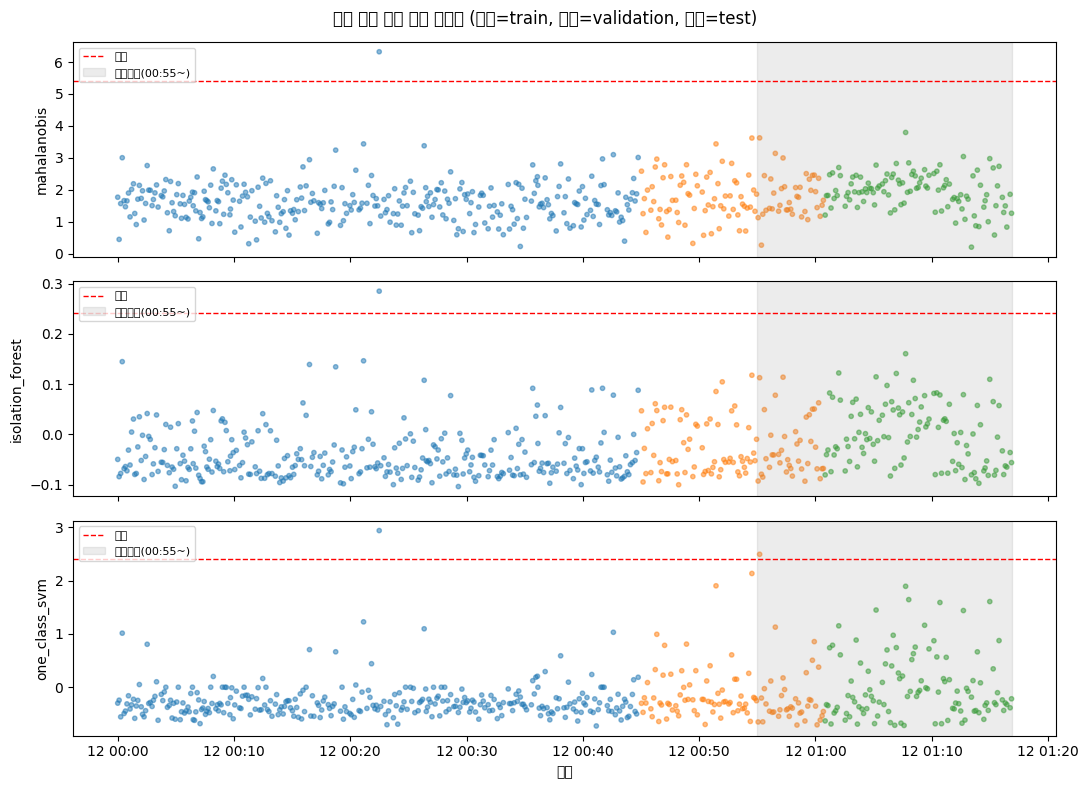

In [12]:
import matplotlib.pyplot as plt

vdip_start = pd.Timestamp('2022-07-12 00:55:00')
in_dip = nrm_all.t_start >= vdip_start

fig, axes = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, (name, (fn, thr)) in zip(axes, MODELS.items()):
    s = fn(nrm_all[FEATURES].to_numpy(float))
    ax.scatter(nrm_all.t_start, s, s=10, alpha=.5, c=np.where(nrm_all.split=='train', 'tab:blue',
               np.where(nrm_all.split=='validation', 'tab:orange', 'tab:green')))
    ax.axhline(thr, color='red', ls='--', lw=1, label='임계')
    ax.axvspan(vdip_start, nrm_all.t_start.max(), color='grey', alpha=.15, label='전환구간(00:55~)')
    ax.set_ylabel(name); ax.legend(loc='upper left', fontsize=8)
    print(f"[{name}] V-dip밖(n={(~in_dip).sum()}) score 평균={s[~in_dip].mean():.3f} 최대={s[~in_dip].max():.3f} | "
          f"V-dip안(n={in_dip.sum()}) score 평균={s[in_dip].mean():.3f} 최대={s[in_dip].max():.3f} "
          f"FP_in_dip={int((s[in_dip]>thr).sum())}")
axes[-1].set_xlabel('시간'); fig.suptitle('정상 전체 구간 점수 시계열 (파랑=train, 주황=validation, 초록=test)')
plt.tight_layout(); plt.show()

**결과:** Mahalanobis는 V-dip 구간(00:55~) 평균 점수가 밖보다 약간 높다(1.92 vs 1.63)
— V자 드리프트가 점수에 미세하게 반영되긴 하지만, 최댓값(3.80)이 임계(5.42)에 한참
못 미쳐 FP는 0이다. Isolation Forest도 같은 패턴(구간 안이 덜 '정상'쪽이지만 임계
근처에도 못 간다, FP 0). **One-Class SVM의 유일한 held-out FP(seg437)가 바로 이
전환구간 진입 시점(00:55:11, n=10으로 짧은 사이클)에서 발생한다** — 세 모델 중 가장
덜 안정적인 SVM이, 가장 불안정한 시간대(드리프트 진입부+짧은 사이클)에서 유일하게
걸린 것은 우연이 아니라 **오경보가 발생할 조건(불안정한 구간 × 짧은 사이클 × 상대적으로
덜 robust한 모델)이 겹쳤을 때 나타난다**는 구체적인 사례다.

## 8. 미탐(FN) 분석 — Isolation Forest가 놓친 4개

의도: 04 이후 줄곧 "미탐 후보 seg3·19·20"으로 불러왔지만, 최종 3개 피처 기준으로
길이별 표(05 ## 6)를 다시 보면 IsolationForest는 **10~19구간 2/4, ≥30구간 8/10**로
실제로는 4개를 놓친다 — 하드케이스 체크가 관성적으로 seg3·19·20만 확인해 네 번째를
놓치고 있었다. 전체 outlier를 다시 스캔해 정확히 어떤 4개인지 특정한다.

In [13]:
maha_fn, maha_thr_ = MODELS['mahalanobis']
iso_fn, iso_thr_ = MODELS['isolation_forest']
X_out_all = ot.loc[ovalid, FEATURES].to_numpy(float)

dfm = pd.DataFrame(X_out_all, columns=FEATURES)
dfm.insert(0, 'seg_id', ot.loc[ovalid, 'seg_id'].to_numpy())
dfm['maha_score'] = maha_fn(X_out_all)
dfm['iso_score'] = iso_fn(X_out_all)
dfm['iso_flag'] = dfm.iso_score > iso_thr_
print(f"Isolation Forest 미탐(iso_flag=False) = {(~dfm.iso_flag).sum()}개")
print(dfm[~dfm.iso_flag].round(3).to_string(index=False))

ref = TABLE['normal'].query("split=='train' and n>=@MIN_N")[FEATURES]
print('\n정상 기준 평균/표준편차:')
print(ref.agg(['mean', 'std']).round(4))
print('\n미탐 4개의 z-score(정상 평균 대비 표준편차 단위):')
miss = dfm[~dfm.iso_flag].set_index('seg_id')[FEATURES]
print(((miss - ref.mean()) / ref.std()).round(1))

Isolation Forest 미탐(iso_flag=False) = 4개
 seg_id  cur_ai0_resid  cur_ai1_resid  normal_center_nrmse  maha_score  iso_score  iso_flag
      3         -0.019          0.023                1.467      81.939      0.157     False
     15          0.250          0.005                1.584      90.503      0.216     False
     19         -0.068         -0.168                2.002     112.059      0.223     False
     20         -0.049         -0.180                5.199     296.314      0.223     False

정상 기준 평균/표준편차:
      cur_ai0_resid  cur_ai1_resid  normal_center_nrmse
mean         0.0000        -0.0000               0.0522
std          0.0142         0.0141               0.0177

미탐 4개의 z-score(정상 평균 대비 표준편차 단위):
        cur_ai0_resid  cur_ai1_resid  normal_center_nrmse
seg_id                                                   
3                -1.3            1.6                 79.9
15               17.6            0.4                 86.5
19               -4.7          -11.9            

**결과:** IsolationForest 미탐은 seg3·15·19·20, 네 개다(seg15가 그동안 하드케이스
목록에 없어 누락되어 있었다). z-score로 보면 패턴이 하나로 깔끔하게 묶이지 않는다:

- **seg19·20**: `cur_ai1_resid`가 뚜렷한 음수(z≈-11.9, -12.8) — 지금까지 "조용함"
  (전류 대비 진동이 과소)으로 불러온 유형과 정확히 일치한다.
- **seg3**: 두 전류잔차가 전부 z<2로 평범하고 `normal_center_nrmse`만 극단적으로
  크다(z≈80) — 조용함과는 다르지만, 전류잔차 쪽에 IsolationForest가 쓸 신호가
  약하다는 점은 같다.
- **seg15**: `cur_ai0_resid`가 오히려 크게 양수(z≈17.6)다 — 이건 "조용함" 패턴이
  아니라 다른 미탐 없이 잡힌 세그먼트들(예: seg13)과 같은 방향이다. 그런데도
  iso_score(0.216)가 임계(0.242)에 근소하게(margin 0.025) 못 미쳐 놓쳤다.

**즉 IsolationForest의 미탐은 "조용함 유형이면 다 놓친다"는 깨끗한 규칙이 아니다.**
절반(19·20)은 그 패턴과 맞지만, 나머지 절반(3·15)은 아니다. seg15는 오히려 Mahalanobis
기준으로는 아주 뚜렷한 이상(score 90.5, 임계 5.4의 17배)인데도 임계 바로 밑에서
놓친다 — 이는 피처 문제가 아니라 **무작위 분할 기반 트리 앙상블 자체의 불안정성**
(6-fold CV에서 IsolationForest TP의 sd가 2.4%p로 세 모델 중 가장 컸던 것)과 같은
현상으로 보는 게 더 맞다.

**주의(9절에서 정정):** 이 4개는 단일 분할 모델 하나의 결과다. fold 기준으로 다시 보면 이 중 3개(15·19·20)는 구조적 미탐이 아니라 그 분할에서만 생긴 우연 이었다 — 9절 참고.

## 9. Fold 기준 재검증 — 단일 분할 미탐 목록이 맞는지 확인

의도: 위 8절의 미탐 목록(seg3·15·19·20)은 **단일 60/20/20 분할로 학습한 모델 하나**
기준이다. 05의 6-fold 블록 CV에서 IsolationForest의 TP가 폴드마다 흔들렸다(sd 2.4%p) —
그렇다면 저 4개 중 일부는 "구조적으로 어려운 것"이 아니라 "그 특정 train 샘플에서
우연히 놓친 것"일 수 있다. 6개 폴드 각각 독립적으로 학습한 모델로 모든 outlier를
다시 채점해, **세그먼트별로 6번 중 몇 번 잡혔는지** 본다. 정상 FP도 같은 방식으로
"out-of-fold"(자기가 held-out일 때) 기준으로 다시 모은다.

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

normal_all = TABLE['normal'][(TABLE['normal'].n >= MIN_N) &
                             np.isfinite(TABLE['normal'][FEATURES]).all(axis=1)].sort_values('t_start').reset_index(drop=True)
Kf = 6
blocks = np.array_split(np.arange(len(normal_all)), Kf)
X_out = ot.loc[ovalid, FEATURES].to_numpy(float)
out_seg_ids = ot.loc[ovalid, 'seg_id'].to_numpy()

normal_fp_log = []
outlier_hits = {name: np.zeros(len(X_out), dtype=int) for name in ['mahalanobis', 'isolation_forest', 'one_class_svm']}
for k in range(Kf):
    te = normal_all.iloc[blocks[k]]
    tr = normal_all.iloc[np.concatenate([blocks[j] for j in range(Kf) if j != k])]
    Xtr = tr[FEATURES].to_numpy(float); Xte = te[FEATURES].to_numpy(float)

    cov = LedoitWolf().fit(Xtr); mean = Xtr.mean(axis=0)
    def maha_k(X, cov=cov, mean=mean):
        d = X - mean; return np.sqrt(np.einsum('ij,jk,ik->i', d, cov.precision_, d))
    maha_thr_k = np.quantile(maha_k(Xtr), COVERAGE)

    iso_k = IsolationForest(n_estimators=300, random_state=0, contamination='auto').fit(Xtr)
    def iso_score_k(X, m=iso_k): return -m.decision_function(X)
    iso_thr_k = np.quantile(iso_score_k(Xtr), COVERAGE)

    scaler_k = StandardScaler().fit(Xtr)
    ocsvm_k = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1).fit(scaler_k.transform(Xtr))
    def ocsvm_score_k(X, m=ocsvm_k, sc=scaler_k): return -m.decision_function(sc.transform(X))
    ocsvm_thr_k = np.quantile(ocsvm_score_k(Xtr), COVERAGE)

    fns_k = {'mahalanobis': (maha_k, maha_thr_k), 'isolation_forest': (iso_score_k, iso_thr_k),
             'one_class_svm': (ocsvm_score_k, ocsvm_thr_k)}
    for name, (fn, thr) in fns_k.items():
        flag_te = fn(Xte) > thr
        for sid, spl, t0, nn, fl in zip(te.seg_id, te.split, te.t_start, te.n, flag_te):
            normal_fp_log.append(dict(fold=k, model=name, seg_id=sid, split=spl, t_start=t0, n=nn, flag=bool(fl)))
        outlier_hits[name] += (fn(X_out) > thr).astype(int)

LOG = pd.DataFrame(normal_fp_log)
print('=== out-of-fold 정상 FP census ===')
for name in ['mahalanobis', 'isolation_forest', 'one_class_svm']:
    sub = LOG[LOG.model == name]; fp = sub[sub.flag]
    print(f"\n[{name}] out-of-fold FP = {len(fp)}/{len(sub)}")
    if len(fp):
        print(fp[['seg_id', 'split', 't_start', 'n', 'fold']].to_string(index=False))

print('\n=== outlier별 6-fold 중 몇 번 잡혔는지 ===')
HIT = pd.DataFrame({'seg_id': out_seg_ids, **{f'{n}_hits/6': outlier_hits[n] for n in outlier_hits}})
print(HIT.to_string(index=False))

=== out-of-fold 정상 FP census ===

[mahalanobis] out-of-fold FP = 1/530
 seg_id split                 t_start  n  fold
    178 train 2022-07-12 00:22:29.076 32     1

[isolation_forest] out-of-fold FP = 1/530
 seg_id split                 t_start  n  fold
    178 train 2022-07-12 00:22:29.076 32     1

[one_class_svm] out-of-fold FP = 2/530
 seg_id split                 t_start  n  fold
    167 train 2022-07-12 00:21:08.408 19     1
    178 train 2022-07-12 00:22:29.076 32     1

=== outlier별 6-fold 중 몇 번 잡혔는지 ===
 seg_id  mahalanobis_hits/6  isolation_forest_hits/6  one_class_svm_hits/6
      1                   6                        6                     6
      2                   6                        6                     6
      3                   6                        1                     6
      4                   6                        6                     6
      6                   6                        6                     6
      7                   6    

**결과 — 8절의 결론을 정정한다.** fold 기준으로 보면 IsolationForest가 **항상(6/6)
놓치는 건 seg3 하나뿐이다.** seg15·19·20은 전부 6/6으로 어느 fold에서 학습한 모델도
놓치지 않는다 — 8절에서 "미탐 4개"로 묶었던 것 중 3개(15·19·20)는 **그 특정
60/20/20 분할의 train 샘플에서만 우연히 놓친 것**이었고, "조용함 유형(음의
`cur_ai1_resid`)이 미탐과 연결된다"는 해석도 이 교차검증 결과로는 뒷받침되지 않는다.

**진짜 구조적 미탐은 seg3뿐이다.** seg3는 `cur_ai0_resid`(z=-1.3)·`cur_ai1_resid`
(z=1.6) 둘 다 평범하고 `normal_center_nrmse`만 이상(z=80)인데, 다른 outlier들(예:
seg20 z=290, seg18 z=140대)은 같은 피처에서 훨씬 더 극단적이다. IsolationForest는
무작위로 피처·분할점을 고르는 방식이라, **3차원 중 1개에서만, 그것도 다른 outlier들보다
덜 극단적으로 벗어난** 점을 고립시키기엔 분할이 더 많이 필요한 것으로 보인다(확정적
기계론은 아니고 관찰된 패턴이다).

정상 FP도 out-of-fold로 다시 보면 Mahalanobis·IsolationForest는 여전히 seg178
(fold1) 하나뿐이고, One-Class SVM은 이전(단일분할)의 seg437 대신 **seg167(같은
fold1 구간)**이 새로 걸린다 — 어떤 세그먼트가 FP가 되는지는 어떤 train 조합이
쓰였는지에 따라 바뀌지만, **전부 fold1 구간(00:11~00:25) 안에서만** 생긴다는 점은
일관된다.

## 9-1. 전체 n 포함 — fold 기준 길이별 재검증

의도: 6~9절은 전부 `n≥10`만 평가했다. 정상 599개 중 69개(11.5%), outlier 21개 중 4개
(19%)가 n<10인데, 이 세그먼트들이 실제로 어떻게 판정되는지 한 번도 본 적이 없다 —
"판정 보류"로 빠진 것과 "판정해봤더니 문제없다"는 다르다. **n=1(정상 9개)은 사인
적합의 자유도(2개) 대비 관측치가 모자라 `normal_center_nrmse`가 수학적으로 정의되지
않는다(NaN)** — 이건 판단의 문제가 아니라 계산 자체가 안 되는 경우라 제외한다. n=2
이상은 전부 계산은 되므로, train은 그대로 n≥10만 쓰고(짧은 사이클로 '정상 기준' 자체를
학습하면 기준이 불안정해진다) **평가는 n≥2 전체를 fold 기준(out-of-fold)으로 돌린다**
— 6·7절처럼 단일 holdout 모델이 아니라, 9절과 같은 방식으로 세 모델 전부 다시 본다.

In [ ]:
from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler

normal_full = TABLE['normal'][np.isfinite(TABLE['normal'][FEATURES]).all(axis=1)].sort_values('t_start').reset_index(drop=True)
outlier_full = TABLE['outlier'][np.isfinite(TABLE['outlier'][FEATURES]).all(axis=1)].copy()
print(f"정상 평가 모집단: {len(normal_full)}/{len(TABLE['normal'])}"
      f" (n=1 NaN {len(TABLE['normal'])-len(normal_full)}개 제외)")
print(f"outlier 평가 모집단: {len(outlier_full)}/{len(TABLE['outlier'])}")

train_eligible = normal_full[normal_full.n >= MIN_N].reset_index(drop=True)
Kf = 6
blocks = np.array_split(np.arange(len(train_eligible)), Kf)
block_edges = [(train_eligible.iloc[b].t_start.min(), train_eligible.iloc[b].t_start.max()) for b in blocks]

def bucket(n):
    if n < 10: return '2~9'
    if n < 20: return '10~19'
    if n < 30: return '20~29'
    return '>=30'

rows = []
for k in range(Kf):
    lo, hi = block_edges[k]
    te = normal_full[(normal_full.t_start >= lo) & (normal_full.t_start <= hi)]
    tr_idx = np.concatenate([blocks[j] for j in range(Kf) if j != k])
    tr = train_eligible.iloc[tr_idx]
    Xtr = tr[FEATURES].to_numpy(float)

    cov = LedoitWolf().fit(Xtr); mean = Xtr.mean(axis=0)
    def maha_k(X, cov=cov, mean=mean):
        d = X - mean; return np.sqrt(np.einsum('ij,jk,ik->i', d, cov.precision_, d))
    maha_thr_k = np.quantile(maha_k(Xtr), COVERAGE)

    iso_k = IsolationForest(n_estimators=300, random_state=0, contamination='auto').fit(Xtr)
    def iso_score_k(X, m=iso_k): return -m.decision_function(X)
    iso_thr_k = np.quantile(iso_score_k(Xtr), COVERAGE)

    scaler_k = StandardScaler().fit(Xtr)
    ocsvm_k = OneClassSVM(kernel='rbf', gamma='scale', nu=0.1).fit(scaler_k.transform(Xtr))
    def ocsvm_score_k(X, m=ocsvm_k, sc=scaler_k): return -m.decision_function(sc.transform(X))
    ocsvm_thr_k = np.quantile(ocsvm_score_k(Xtr), COVERAGE)

    models_k = {'mahalanobis': (maha_k, maha_thr_k), 'isolation_forest': (iso_score_k, iso_thr_k),
                'one_class_svm': (ocsvm_score_k, ocsvm_thr_k)}
    for name, (fn, thr) in models_k.items():
        Xte = te[FEATURES].to_numpy(float)
        for sid, nn, fl in zip(te.seg_id, te.n, fn(Xte) > thr):
            rows.append(dict(model=name, label='normal', seg_id=sid, n=nn, fold=k, flag=bool(fl)))
        Xout = outlier_full[FEATURES].to_numpy(float)
        for sid, nn, fl in zip(outlier_full.seg_id, outlier_full.n, fn(Xout) > thr):
            rows.append(dict(model=name, label='outlier', seg_id=sid, n=nn, fold=k, flag=bool(fl)))

FULLN = pd.DataFrame(rows)
FULLN['bucket'] = FULLN.n.apply(bucket)

print('\n=== 길이 구간별 FP/TP율 (out-of-fold 전체 풀링) ===')
for label in ['normal', 'outlier']:
    sub = FULLN[FULLN.label == label]
    piv = sub.groupby(['model', 'bucket']).agg(표본=('flag', 'size'), 플래그=('flag', 'sum'))
    piv['비율%'] = (piv.플래그 / piv.표본 * 100).round(1)
    print(f"\n[{label}]")
    print(piv.to_string())

**결과 — 짧은 사이클(n=2~9)에서 오탐률이 크게 뛴다.** 세 모델 모두 n≥10에서는 전과
동일하게 거의 0%인데, **n=2~9에서는 Mahalanobis 32.2%, One-Class SVM 42.4%,
Isolation Forest 6.8%**로 뛴다 — 지금까지 "보류"로 빼뒀던 11.5%의 정상 사이클을
실제로 판정시키면, 채택 모델(Mahalanobis)조차 셋 중 하나는 오탐이라는 뜻이다. 반면
**Isolation Forest는 이 구간에서 가장 안정적이다**(6.8%) — n≥10에서는 seg3를 구조적으로
놓치는 약점이 있었지만(9절), 짧은 사이클에서는 오히려 세 모델 중 제일 덜 흔들린다.

outlier TP는 이 구간에서도 세 모델 다 100%지만, 같은 구간의 FP가 이렇게 높다는 걸
감안하면 "잘 탐지한다"가 아니라 **"짧은 사이클은 정상·이상 가릴 것 없이 쉽게 플래그된다"**
는 뜻으로 읽어야 한다 — 변별력이 없는 상태에서 전부 양성으로 찍은 것과 다르지 않다.
n=1(정상 9개)은 `normal_center_nrmse`가 NaN이라 어느 모델로도 판정이 불가능하다(계산
자체가 안 됨).

In [ ]:
import matplotlib.pyplot as plt

order = ['2~9', '10~19', '20~29', '>=30']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, label in zip(axes, ['normal', 'outlier']):
    sub = FULLN[FULLN.label == label]
    piv = sub.groupby(['model', 'bucket']).flag.mean().unstack('bucket')[order] * 100
    piv.T.plot.bar(ax=ax)
    ax.set_ylabel('플래그 비율(%)')
    ax.set_xlabel('세그먼트 길이 구간(샘플 수)')
    ax.set_title('정상(오탐률)' if label == 'normal' else 'outlier(탐지율)')
    ax.legend(fontsize=8)
fig.suptitle('길이 구간별 플래그 비율 — out-of-fold, 전체 n 포함')
plt.tight_layout(); plt.show()

## 9-2. 04 rule-base도 같은 문제인가

의도: n<10에서의 오탐 폭증이 one-class 모델 세 개만의 문제인지, 애초에 피처
(`normal_center_nrmse` 등) 자체가 짧은 사이클에서 불안정해서 생기는 문제인지
확인한다. `04_rule_base.ipynb`의 원래 규칙(피처별 train 99.9% 분위수, OR 결합)을
그대로 가져와 같은 6-fold out-of-fold 방식으로 전체 n에 돌린다. `04`의 임계는
단일 분할로 한 번만 추정했으므로, 공정한 비교를 위해 여기서도 폴드마다 새로
추정한다.

In [ ]:
FEATURES6 = ['ai0_rms', 'ai1_rms', 'cur_ai0_resid', 'cur_ai1_resid', 'ratio_ai1_ai0', 'normal_center_nrmse']
TWO_SIDED = {'cur_ai0_resid', 'cur_ai1_resid', 'ratio_ai1_ai0'}
RULES = {'nrmse_only': ['normal_center_nrmse'], 'all_6_OR': FEATURES6}

normal_full6 = TABLE['normal'][np.isfinite(TABLE['normal'][FEATURES6]).all(axis=1)].sort_values('t_start').reset_index(drop=True)
outlier_full6 = TABLE['outlier'][np.isfinite(TABLE['outlier'][FEATURES6]).all(axis=1)].copy()
train_eligible6 = normal_full6[normal_full6.n >= MIN_N].reset_index(drop=True)
blocks6 = np.array_split(np.arange(len(train_eligible6)), Kf)
edges6 = [(train_eligible6.iloc[b].t_start.min(), train_eligible6.iloc[b].t_start.max()) for b in blocks6]

rows = []
for k in range(Kf):
    lo, hi = edges6[k]
    te = normal_full6[(normal_full6.t_start >= lo) & (normal_full6.t_start <= hi)]
    tr = train_eligible6.iloc[np.concatenate([blocks6[j] for j in range(Kf) if j != k])]

    thr_k = {}
    for feature in FEATURES6:
        values = tr[feature]
        lo_q = values.quantile((1 - COVERAGE) / 2) if feature in TWO_SIDED else -np.inf
        hi_q = values.quantile(1 - (1 - COVERAGE) / 2 if feature in TWO_SIDED else COVERAGE)
        thr_k[feature] = (lo_q, hi_q)

    def predict_k(table, feats, thr=thr_k):
        alarm = pd.Series(False, index=table.index)
        for f in feats:
            lo_, hi_ = thr[f]
            alarm |= (table[f] < lo_) | (table[f] > hi_)
        return alarm

    for rule, feats in RULES.items():
        for sid, nn, al in zip(te.seg_id, te.n, predict_k(te, feats)):
            rows.append(dict(rule=rule, label='normal', seg_id=sid, n=nn, fold=k, flag=bool(al)))
        for sid, nn, al in zip(outlier_full6.seg_id, outlier_full6.n, predict_k(outlier_full6, feats)):
            rows.append(dict(rule=rule, label='outlier', seg_id=sid, n=nn, fold=k, flag=bool(al)))

RULE_RES = pd.DataFrame(rows)
RULE_RES['bucket'] = RULE_RES.n.apply(bucket)
for label in ['normal', 'outlier']:
    print(f"\n=== {label} (04 rule-base, fold 기준, 전체 n) ===")
    sub = RULE_RES[RULE_RES.label == label]
    piv = sub.groupby(['rule', 'bucket']).agg(표본=('flag', 'size'), 플래그=('flag', 'sum'))
    piv['비율%'] = (piv.플래그 / piv.표본 * 100).round(1)
    print(piv.to_string())

**결과: 04 rule-base도 같은 병을 앓는다 — 오히려 더 심하다.** `nrmse_only`(04의
기준선 규칙)는 n=2~9에서 오탐률 18.6%, `all_6_OR`은 40.7%다. one-class 모델들과
비교하면:

| 모델/규칙 | n=2~9 오탐률 | n=2~9 탐지율 |
|---|---:|---:|
| Mahalanobis | 32.2% | 100% |
| One-Class SVM | 42.4% | 100% |
| Isolation Forest | 6.8% | 100% |
| 04 nrmse_only | 18.6% | **79.2%(19/24)** |
| 04 all_6_OR | 40.7% | 100% |

**04 nrmse_only만 유일하게 짧은 outlier를 실제로 놓친다(미탐 5/24)** — one-class
모델들은 오탐이 늘어도 outlier는 전부 잡았는데, 단일 피처 규칙은 짧은 길이에서
탐지력 자체가 무너진다. 결론: **n<10 불안정성은 특정 모델의 결함이 아니라
`normal_center_nrmse` 등 피처 자체가 짧은 사이클에서 통계적으로 불안정해지는
근본 문제**다. 04(규칙)부터 05(one-class) 전부가 이 문제를 공유하므로, 해결책도
모델 교체가 아니라 **피처·전처리 수준**(병합, 별도 임계, 혹은 판단 보류 유지)에서
찾아야 한다.

## 10. 시각화 — 피처 공간에서 오탐·미탐이 왜 경계에 있는지

의도: 표와 z-score만으로는 "경계 근처"가 실제로 얼마나 가까운지 직관적으로 보기
어렵다. 정상(test)·outlier를 피처 평면에 같이 찍고, 실제로 문제가 됐던 점들
(FP: seg178·167·437, 진짜 미탐: seg3)을 표시해 왜 거기서 애매한지 눈으로 확인한다.

/tmp/ipykernel_20286/1980609219.py:31: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/1980609219.py:31: UserWarning: Glyph 47448 (\N{HANGUL SYLLABLE RYU}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/1980609219.py:31: UserWarning: Glyph 51092 (\N{HANGUL SYLLABLE JAN}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/1980609219.py:31: UserWarning: Glyph 52264 (\N{HANGUL SYLLABLE CA}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/1980609219.py:31: UserWarning: Glyph 54217 (\N{HANGUL SYLLABLE PYEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/1980609219.py:31: UserWarning: Glyph 47732 (\N{HANGUL SYLLABLE MYEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout(); plt.show()
/tmp/ipykernel_20286/1980609219.py:31: UserWarning: G

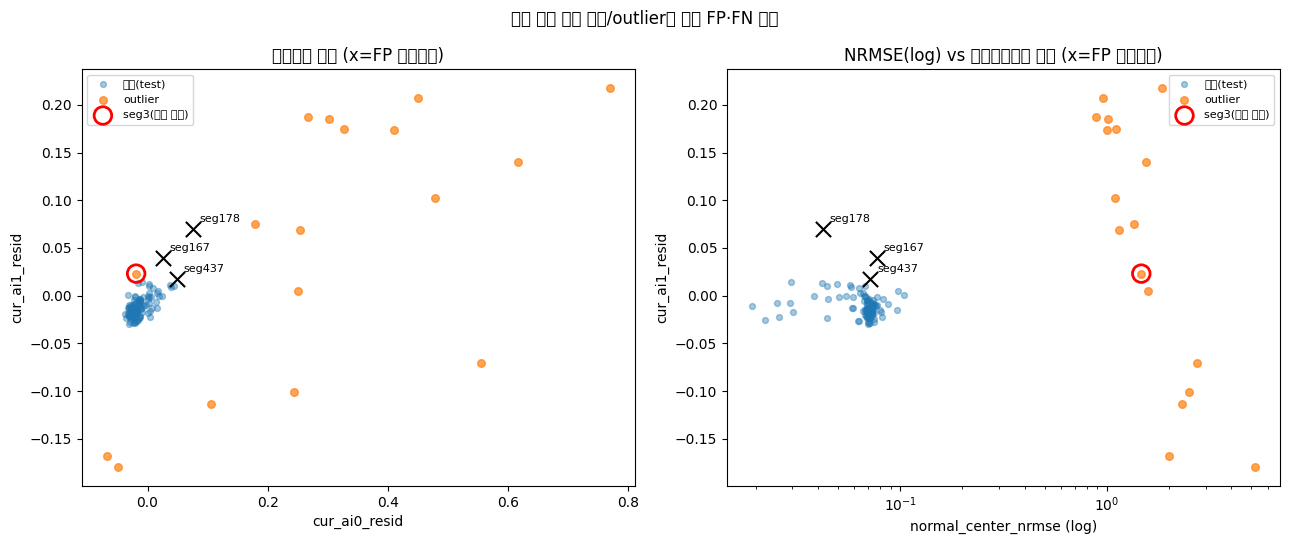

In [15]:
import matplotlib.pyplot as plt

nt_test = TABLE['normal'].query("split=='test' and n>=@MIN_N")
fp_segs = {178: 'FP(Mahalanobis·IF, train)', 167: 'FP(SVM, out-of-fold)', 437: 'FP(SVM, 단일분할)'}
fp_rows = TABLE['normal'][TABLE['normal'].seg_id.isin(fp_segs)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

ax = axes[0]
ax.scatter(nt_test.cur_ai0_resid, nt_test.cur_ai1_resid, s=18, alpha=.4, color='tab:blue', label='정상(test)')
ax.scatter(ot.loc[ovalid,'cur_ai0_resid'], ot.loc[ovalid,'cur_ai1_resid'], s=30, alpha=.7, color='tab:orange', label='outlier')
seg3_row = ot[ot.seg_id==3].iloc[0]
ax.scatter([seg3_row.cur_ai0_resid], [seg3_row.cur_ai1_resid], s=160, facecolors='none', edgecolors='red', linewidths=2, label='seg3(진짜 미탐)')
for sid, row in fp_rows.iterrows():
    ax.scatter([row.cur_ai0_resid], [row.cur_ai1_resid], marker='x', s=120, color='black')
    ax.annotate(f'seg{row.seg_id}', (row.cur_ai0_resid, row.cur_ai1_resid), xytext=(5,5), textcoords='offset points', fontsize=8)
ax.set_xlabel('cur_ai0_resid'); ax.set_ylabel('cur_ai1_resid'); ax.legend(fontsize=8)
ax.set_title('전류잔차 평면 (x=FP 세그먼트)')

ax = axes[1]
ax.scatter(nt_test.normal_center_nrmse, nt_test.cur_ai1_resid, s=18, alpha=.4, color='tab:blue', label='정상(test)')
ax.scatter(ot.loc[ovalid,'normal_center_nrmse'], ot.loc[ovalid,'cur_ai1_resid'], s=30, alpha=.7, color='tab:orange', label='outlier')
ax.scatter([seg3_row.normal_center_nrmse], [seg3_row.cur_ai1_resid], s=160, facecolors='none', edgecolors='red', linewidths=2, label='seg3(진짜 미탐)')
for sid, row in fp_rows.iterrows():
    ax.scatter([row.normal_center_nrmse], [row.cur_ai1_resid], marker='x', s=120, color='black')
    ax.annotate(f'seg{row.seg_id}', (row.normal_center_nrmse, row.cur_ai1_resid), xytext=(5,5), textcoords='offset points', fontsize=8)
ax.set_xscale('log'); ax.set_xlabel('normal_center_nrmse (log)'); ax.set_ylabel('cur_ai1_resid')
ax.legend(fontsize=8); ax.set_title('NRMSE(log) vs 하부전류잔차 평면 (x=FP 세그먼트)')

fig.suptitle('피처 평면 위의 정상/outlier와 실제 FP·FN 위치')
plt.tight_layout(); plt.show()

**결과:** 왼쪽(전류잔차 평면)에서 **seg3(빨간 원)는 정상 군집의 가장자리에 거의
붙어 있다** — outlier 중에서도 유일하게 정상과 거의 구분이 안 되는 위치다. 반면
오른쪽(NRMSE 축 포함) 평면에서는 seg3가 정상 군집에서 명확히 떨어져 있다 — **seg3는
"전류잔차 2개로는 안 보이고 NRMSE 1개로만 보이는" 이상**이라는 8~9절의 결론이 그래프로도
그대로 확인된다.

FP 세그먼트(seg178·167·437, X 표시)는 정상 군집 중에서는 꼬리 쪽(z≈1.2~5.3)에 있지만,
**진짜 outlier(z 80~290, 8절)와는 비교가 안 될 만큼 작은 편차다** — "정상이지만 정상
중에서는 가장 바깥쪽"과 "진짜 이상" 사이의 간격이 그래프에서도 뚜렷하게 보인다. 이는
6절의 "경계선 근처의 고립된 사례"라는 설명과 일치한다.

## 11. 결론 — 오경보·미탐 발생조건 요약

**오경보(FP) 조건(n≥10)**: 전체 정상 530개 중 Mahalanobis·IsolationForest는 단 1개(train
내부, 정의상 예상되는 수), held-out(validation+test, 217개) 기준으로는 **0개**다.
One-Class SVM만 held-out 1개를 내고, out-of-fold로 다시 봐도 어떤 모델이든 FP는
**fold1 구간(00:11:49~00:25:10)에서만** 나온다 — 세 모델이 공통으로 민감해지는 특정
시간대가 있다는 뜻이다. 모든 모델에서 연속 오경보(run length ≥2)가 전혀 없어, N중M
지속성 규칙이 가정하는 실패 모드(간헐적 연속 오탐) 자체가 이 데이터에 없다는 결론은
유지된다.

**미탐(FN) 조건(n≥10)**: Mahalanobis·One-Class SVM은 6-fold 전체에서 0건. IsolationForest는
단일 분할 기준 4건처럼 보였지만, **fold 기준으로 재검증하면 구조적 미탐은 seg3 하나뿐**
이다(6개 독립 모델 중 1개만 탐지) — 나머지 3개(15·19·20)는 그 특정 분할의 train
샘플에서만 우연히 놓친 것이었다. seg3의 특징은 3개 피처 중 `normal_center_nrmse`
하나에서만 이상이고(z=80), 다른 2개는 평범하며(|z|<2), 그 하나의 피처에서도 다른
outlier들보다 덜 극단적이다 — IsolationForest의 무작위 분할 방식이 "한 축에서만,
그것도 상대적으로 약하게" 벗어난 점을 고립시키는 데 약하다는 정황이다.

**n<10은 완전히 다른 그림이고(9-1·9-2절), 모델 문제가 아니라 피처 문제다.**
지금까지 "판정 보류"로 뒀던 짧은 사이클(정상 11.5%, outlier 19%)을 실제로 fold 기준
으로 판정시켜보면, 채택 모델(Mahalanobis)조차 오탐률 32.2%다(One-Class SVM 42.4%,
IsolationForest 6.8%). **04의 rule-base 규칙도 같은 구간에서 오탐률 18.6~40.7%로
무너지고, 그중 `nrmse_only`는 짧은 outlier를 실제로 5/24 놓친다** — one-class 세
모델은 전부 TP 100%였는데 단일 피처 규칙만 탐지력도 같이 무너진 것이다. 04(규칙)부터
05(one-class) 전부가 같은 문제를 공유한다는 건, 원인이 특정 모델의 결함이 아니라
**`normal_center_nrmse`를 포함한 피처 자체가 짧은 사이클에서 통계적으로 불안정**
해진다는 뜻이다(사인 적합 자유도 부족, n=1은 아예 NaN). 흥미롭게도 n≥10에서 가장
불안정했던 IsolationForest가 n=2~9에서는 one-class 중 가장 안정적이다 — 모델 우열이
길이 구간마다 뒤집힌다.

**종합**: 채택 모델(Mahalanobis)은 n≥10 구간(정상 530개·outlier 17개, 전체의 88.5%/81%)
에서는 6-fold 교차검증 전부 FP 0, FN 0으로 완벽하다. 하지만 **이 완벽함은 n≥10이라는
전제 위에서만 성립하고, 그 한계는 04부터 이어진 피처 자체의 한계**다. "미탐지·오경보
발생조건"의 가장 중요한 조건 하나는 결국 **모델 선택이 아니라 세그먼트 길이**였다.